In [9]:
from pathlib import Path
import os, sys

# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add notebook-local modules to import path
src_candidates = [
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in src_candidates:
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))
        break
print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint/code_repository


In [10]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "figure3"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()


# text vs no_text comparison

/tmp/ipykernel_6553/1232413693.py:353: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(


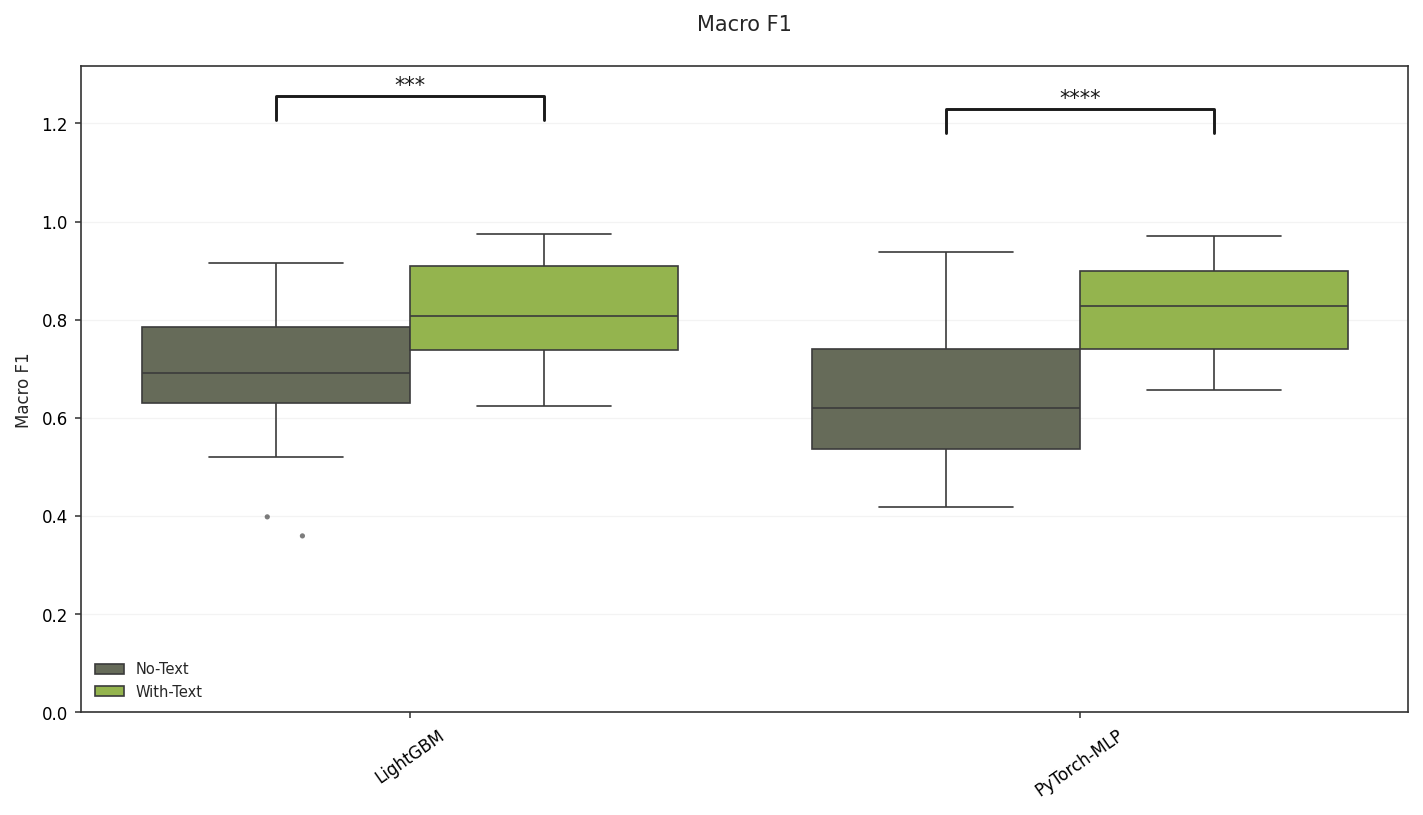

Saved plot: analysis_exports/text_vs_notext_proteomics_grouped_stars/grouped_box_proteomics_macro_f1_stars.png


/tmp/ipykernel_6553/1232413693.py:353: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(


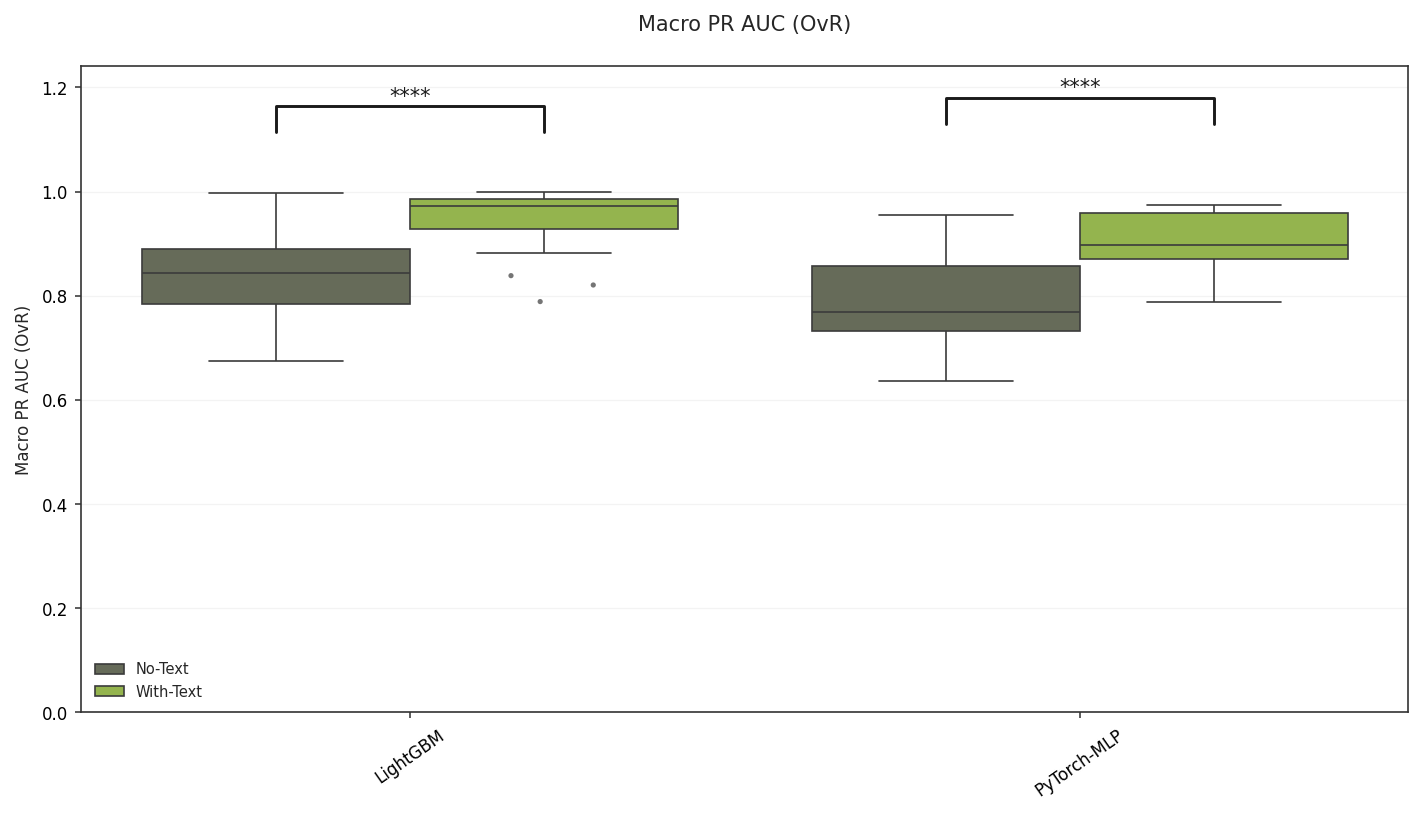

Saved plot: analysis_exports/text_vs_notext_proteomics_grouped_stars/grouped_box_proteomics_macro_ap_ovr_stars.png


/tmp/ipykernel_6553/1232413693.py:353: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(


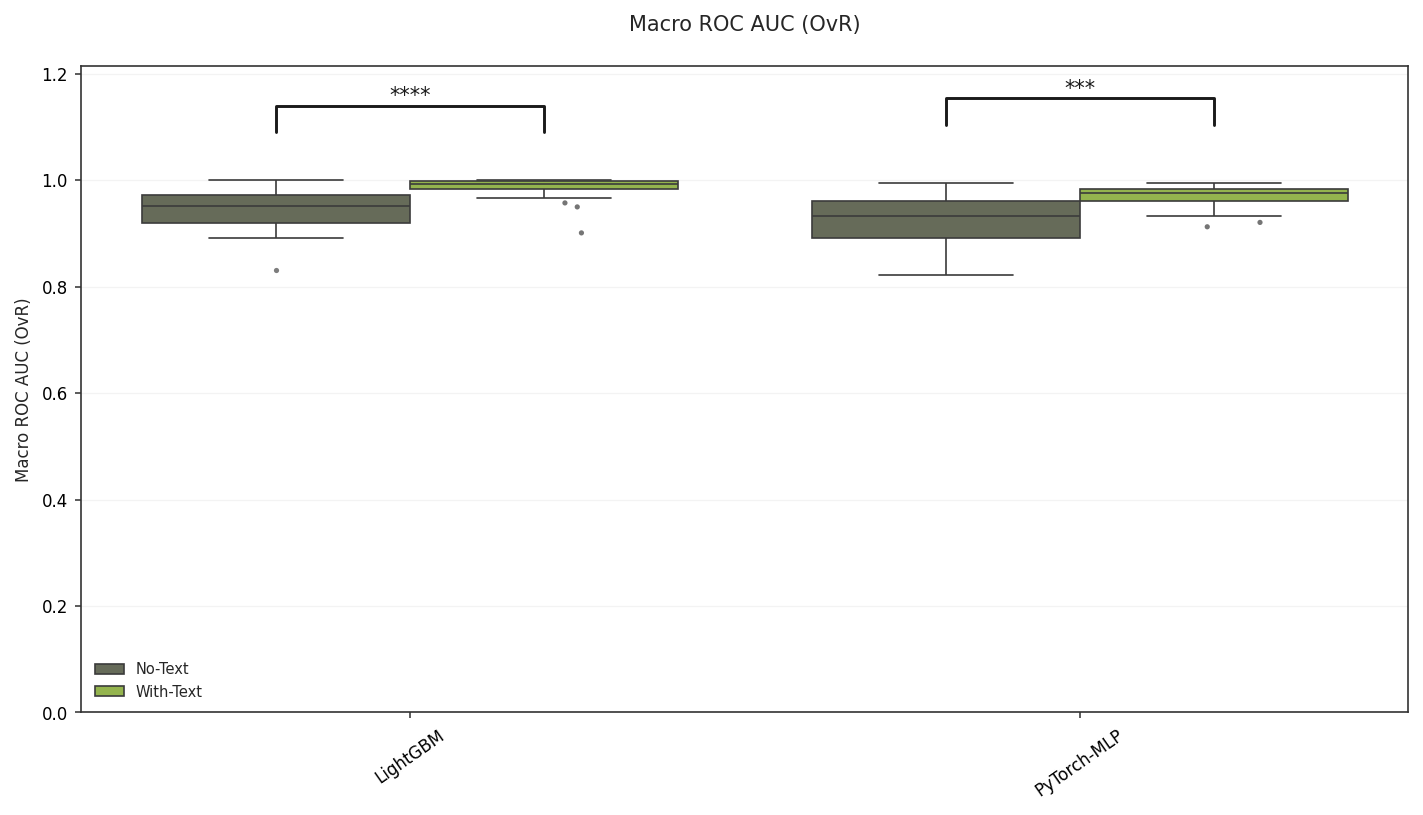

Saved plot: analysis_exports/text_vs_notext_proteomics_grouped_stars/grouped_box_proteomics_macro_roc_ovr_stars.png

Overall Friedman omnibus per metric (decision uses p_raw < alpha_bonf):
   metric_key  p_friedman_raw  n_cycles_balanced  alpha_bonferroni  friedman_sig_after_alpha_bonf
     macro_f1    1.036760e-06                 25          0.016667                           True
 macro_ap_ovr    1.314728e-10                 25          0.016667                           True
macro_roc_ovr    5.008645e-11                 25          0.016667                           True

Per-model paired comparisons (With-Text vs No-Text), Bonferroni across metrics:
  [LightGBM] Macro F1: Δ=+0.1253 (95% CI +0.0710,+0.1797), t-test p=7.645e-05, dz=0.952, Bonf α=0.017
  [LightGBM] Macro PR AUC (OvR): Δ=+0.1065 (95% CI +0.0765,+0.1366), t-test p=1.466e-07, dz=1.464, Bonf α=0.017
  [LightGBM] Macro ROC AUC (OvR): Δ=+0.0384 (95% CI +0.0254,+0.0514), t-test p=2.738e-06, dz=1.218, Bonf α=0.017
  [PyTorch-

In [11]:
# -*- coding: utf-8 -*-
"""
WITH-TEXT vs NO-TEXT on Proteomics only, grouped by model (LightGBM then PyTorch-MLP).
Adds classic significance bars with stars above each model's paired comparison.

- Overall Friedman test (balanced cycles across the 4 groups).
- One boxplot per metric:
    Macro F1, Macro PR AUC (OvR), Macro ROC AUC (OvR)
- Boxplot styling matches your prior code (whis=1.5, outlier dots optional, fonts, grid).

Author: you
"""
import matplotlib.patches as mpatches
import os, glob, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ---------------------- USER CONFIG ----------------------
EXP_TEXT_ROOT   = "predictions/Text_vs_No_Text_experiment/multiclass"      # pairwise->multiclass experiment root
EXP_NOTEXT_ROOT = "predictions/Text_vs_No_Text_experiment/no_text"   # true multiclass experiment root

MODELS = [
    ("lightgbm",     "LightGBM"),
    ("pytorch_mlp",  "PyTorch-MLP"),
]
METRICS = [
    ("macro_f1",     "Macro F1",           True),   # (key, label, clamp_01)
    ("macro_ap_ovr", "Macro PR AUC (OvR)", True),
    ("macro_roc_ovr","Macro ROC AUC (OvR)",True),
]
SHOW_POINTS = "outliers"   # "outliers" | "all" | "none"
WHIS = 1.5
XTICK_SIZE = 10
YTICK_SIZE = 10
YLABEL_SIZE = 10
XROT = 35

OUT_DIR = "analysis_exports/text_vs_notext_proteomics_grouped_stars"
os.makedirs(OUT_DIR, exist_ok=True)
# --------------------------------------------------------

def _extract_keys_from_filename(path: str):
    base = os.path.basename(path).replace(".pkl","")
    kv = {}
    for token in base.split("_"):
        if token.startswith("fold"): kv["fold_idx"] = int(token.replace("fold",""))
        if token.startswith("iter"): kv["cv_iter"] = int(token.replace("iter",""))
        if token.startswith("rep"):  kv["rep_idx"]  = int(token.replace("rep",""))
        if token.startswith("seed"): kv["seed"]     = int(token.replace("seed",""))
    return kv

def _load_pkls(run_dir: str):
    pkls = sorted(glob.glob(os.path.join(run_dir, "*.pkl")))
    if not pkls:
        pkls = sorted(glob.glob(os.path.join(run_dir, "**", "*.pkl"), recursive=True))
    return pkls

def _is_pairwise_agg(df: pd.DataFrame) -> bool:
    return ("TrueMoA" in df.columns) and ("PredMoA" in df.columns)

def _is_notext_fold(df: pd.DataFrame) -> bool:
    return ("TrueLbl" in df.columns) and ("PredLbl" in df.columns)

def _metric_pack():
    return {"macro_f1": np.nan, "macro_ap_ovr": np.nan, "macro_roc_ovr": np.nan}

def _metrics_pairwise_agg(df: pd.DataFrame):
    from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
    out = _metric_pack()
    y_true = df["TrueMoA"].values
    y_pred = df["PredMoA"].values
    present = np.unique(y_true)
    out["macro_f1"] = f1_score(y_true, y_pred, average="macro", labels=present, zero_division=0)
    ovrs_roc, ovrs_ap = [], []
    for c in present:
        if c not in df.columns: 
            continue
        y_bin = (y_true == c).astype(int)
        s_c = df[c].to_numpy()
        if y_bin.sum() == 0 or y_bin.sum() == len(y_bin):
            continue
        try:
            ovrs_roc.append(roc_auc_score(y_bin, s_c))
            ovrs_ap.append(average_precision_score(y_bin, s_c))
        except ValueError:
            pass
    out["macro_roc_ovr"] = float(np.mean(ovrs_roc)) if ovrs_roc else np.nan
    out["macro_ap_ovr"]  = float(np.mean(ovrs_ap))  if ovrs_ap  else np.nan
    return out

def _metrics_notext(df: pd.DataFrame):
    from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
    out = _metric_pack()
    y_true = df["TrueLbl"].values
    y_pred = df["PredLbl"].values
    present = np.unique(y_true)
    out["macro_f1"] = f1_score(y_true, y_pred, average="macro", labels=present, zero_division=0)
    ovrs_roc, ovrs_ap = [], []
    proba_cols = [c for c in df.columns if c.startswith("proba_")]
    for c in present:
        key = "proba_"+str(c)
        if key not in df.columns:
            continue
        y_bin = (y_true == c).astype(int)
        s_c = df[key].to_numpy()
        if y_bin.sum() == 0 or y_bin.sum() == len(y_bin):
            continue
        try:
            ovrs_roc.append(roc_auc_score(y_bin, s_c))
            ovrs_ap.append(average_precision_score(y_bin, s_c))
        except ValueError:
            pass
    out["macro_roc_ovr"] = float(np.mean(ovrs_roc)) if ovrs_roc else np.nan
    out["macro_ap_ovr"]  = float(np.mean(ovrs_ap))  if ovrs_ap  else np.nan
    return out

def _load_fold_table(run_dir: str) -> pd.DataFrame:
    rows = []
    for p in _load_pkls(run_dir):
        try:
            df = pd.read_pickle(p)
        except Exception:
            continue
        is_pw = _is_pairwise_agg(df); is_nt = _is_notext_fold(df)
        if not (is_pw or is_nt):
            continue
        keys = _extract_keys_from_filename(p)
        for k in ["cv_iter","fold_idx","rep_idx","seed"]:
            if (k in df.columns) and (len(df[k]) > 0):
                keys[k] = df[k].iloc[0]
        metrics = _metrics_pairwise_agg(df) if is_pw else _metrics_notext(df)
        rows.append({**keys, **metrics})
    out = pd.DataFrame(rows)
    return out.dropna(subset=["cv_iter","fold_idx","rep_idx"])

def _find_run_dir_text(exp_root: str, model_key: str) -> str:
    hits = []
    for d, _, files in os.walk(exp_root):
        if any(f.endswith(".pkl") for f in files):
            base = os.path.basename(d)
            if (model_key in base) and base.endswith("Text_Embedding+Proteomics"):
                hits.append(d)
    if hits:
        return sorted(hits, key=len)[0]
    for d, _, files in os.walk(exp_root):
        if any(f.endswith(".pkl") for f in files):
            base = os.path.basename(d)
            if (model_key in base) and ("Text_Embedding" in base) and ("Proteomics" in base):
                return d
    raise FileNotFoundError(f"with-text run not found for model={model_key} under {exp_root}")

def _find_run_dir_notext(exp_root: str, model_key: str) -> str:
    target = f"no_text__{model_key}_Proteomics"
    for d, _, files in os.walk(exp_root):
        if os.path.basename(d) == target and any(f.endswith(".pkl") for f in files):
            return d
    for d, _, files in os.walk(exp_root):
        base = os.path.basename(d)
        if base.startswith(f"no_text__{model_key}_") and base.endswith("Proteomics") and any(f.endswith(".pkl") for f in files):
            return d
    raise FileNotFoundError(f"no-text run not found for model={model_key} under {exp_root}")

def _paired_t_and_ci(x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    mask = ~(np.isnan(x) | np.isnan(y))
    x, y = x[mask], y[mask]
    n = len(x)
    if n < 3:
        return dict(n=n, t=np.nan, p=np.nan, mean_diff=np.nan, ci_low=np.nan, ci_high=np.nan, dz=np.nan)
    diffs = x - y
    mean_diff = float(np.mean(diffs))
    sd_diff = float(np.std(diffs, ddof=1))
    t_stat, p_val = stats.ttest_rel(x, y, nan_policy="omit")
    se = sd_diff / math.sqrt(n)
    tcrit = stats.t.ppf(0.975, df=n-1)
    ci_low, ci_high = mean_diff - tcrit*se, mean_diff + tcrit*se
    dz = mean_diff / sd_diff if sd_diff > 0 else np.inf
    return dict(n=n, t=float(t_stat), p=float(p_val), mean_diff=mean_diff, ci_low=float(ci_low), ci_high=float(ci_high), dz=float(dz))

# ---------------------- LOAD & ALIGN ----------------------
tidy_rows = []
paired_stats_rows = []
per_model_tables = {}

for model_key, model_name in MODELS:
    dir_text   = _find_run_dir_text(EXP_TEXT_ROOT,   model_key)
    dir_notext = _find_run_dir_notext(EXP_NOTEXT_ROOT, model_key)

    df_text   = _load_fold_table(dir_text)
    df_notext = _load_fold_table(dir_notext)

    on = ["cv_iter","fold_idx","rep_idx"]
    merged = pd.merge(
        df_text[on + [m[0] for m in METRICS]].add_prefix("W_"),
        df_notext[on + [m[0] for m in METRICS]].add_prefix("N_"),
        left_on=[f"W_{c}" for c in on],
        right_on=[f"N_{c}" for c in on],
        how="inner"
    )
    merged["cv_cycle"] = merged[["W_cv_iter","W_fold_idx","W_rep_idx"]].astype(int).astype(str).agg("|".join, axis=1)
    per_model_tables[model_name] = merged.copy()

    # tidy rows & paired stats
    for metric_key, _, _ in METRICS:
        # With-Text
        tidy_rows += [{
            "cv_cycle": merged["cv_cycle"].iloc[i],
            "Model": model_name,
            "Method": "With-Text",
            "metric_key": metric_key,
            "value": merged[f"W_{metric_key}"].iloc[i]
        } for i in range(len(merged))]
        # No-Text
        tidy_rows += [{
            "cv_cycle": merged["cv_cycle"].iloc[i],
            "Model": model_name,
            "Method": "No-Text",
            "metric_key": metric_key,
            "value": merged[f"N_{metric_key}"].iloc[i]
        } for i in range(len(merged))]

        res = _paired_t_and_ci(merged[f"W_{metric_key}"], merged[f"N_{metric_key}"])
        paired_stats_rows.append({
            "Model": model_name,
            "metric_key": metric_key,
            **res
        })

tidy = pd.DataFrame(tidy_rows)
paired_stats = pd.DataFrame(paired_stats_rows)

# Bonferroni across metrics per model
alpha = 0.05
for model_name in paired_stats["Model"].unique():
    m = paired_stats.loc[paired_stats["Model"] == model_name, "p"].notna().sum()
    adj = alpha / max(1, m)
    idx = paired_stats["Model"] == model_name
    paired_stats.loc[idx, "alpha_bonferroni"] = adj
    paired_stats.loc[idx, "p_bonferroni"] = (paired_stats.loc[idx, "p"] * m).clip(upper=1.0)
    paired_stats.loc[idx, "sig_after_bonf"] = paired_stats.loc[idx, "p_bonferroni"] < alpha

# Save tables
tidy.to_csv(os.path.join(OUT_DIR, "tidy_proteomics_cycles.csv"), index=False)
paired_stats.to_csv(os.path.join(OUT_DIR, "paired_stats_per_model.csv"), index=False)

# ---------------------- FRIEDMAN TEST (Overall) ----------------------
def friedman_overall(df_metric: pd.DataFrame):
    """Friedman across 4 groups (Model × Method) on balanced cycles only."""
    try:
        import pingouin as pg
    except Exception:
        print("pingouin not installed; skipping Friedman.")
        return np.nan, None

    df = df_metric[["cv_cycle","Model","Method","value"]].dropna().copy()
    df["group"] = df["Model"] + " | " + df["Method"]

    k = df["group"].nunique()
    ok = (df.groupby("cv_cycle")["group"].nunique() == k)
    df_bal = df[df["cv_cycle"].isin(ok[ok].index)].copy()
    if df_bal.empty:
        return np.nan, None

    tab = pg.friedman(data=df_bal.rename(columns={"value":"score"}),
                      dv="score", within="group", subject="cv_cycle")
    if "p-unc" in tab.columns: pval = float(tab["p-unc"].iloc[0])
    elif "p" in tab.columns:   pval = float(tab["p"].iloc[0])
    else:                      pval = np.nan
    return pval, df_bal

# --------------- helpers for significance star overlays ---------------
def p_to_stars(p):
    if p < 1e-4: return "****"
    if p < 1e-3: return "***"
    if p < 1e-2: return "**"
    if p < 0.05: return "*"
    return "ns"

def add_sig_bar(ax, x1, x2, y, h, text, lw=1.2):
    """Draw a significance bar with text above two x positions."""
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=lw, c="k")
    ax.text((x1+x2)/2, y+h, text, ha='center', va='bottom', color='k', fontsize=9)

# ---------------------- PLOTTING ----------------------
apply_style()
model_order  = [name for _, name in MODELS]   # ["LightGBM","PyTorch-MLP"]
method_order = ["No-Text", "With-Text"]
palette = {"No-Text": "#676E56", "With-Text": "#9BC53D"}

# Friedman omnibus per metric + Bonferroni across metrics (family = Figure 3d metrics)
friedman_rows = []
for metric_key, _, _ in METRICS:
    dfp_metric = tidy[tidy["metric_key"] == metric_key].dropna().copy()
    p_friedman_raw, df_bal = friedman_overall(dfp_metric)
    n_cycles_bal = int(df_bal["cv_cycle"].nunique()) if isinstance(df_bal, pd.DataFrame) and not df_bal.empty else 0
    friedman_rows.append({
        "metric_key": metric_key,
        "p_friedman_raw": p_friedman_raw,
        "n_cycles_balanced": n_cycles_bal,
    })

friedman_stats = pd.DataFrame(friedman_rows)
alpha_family_friedman = 0.05
m_friedman = int(friedman_stats["p_friedman_raw"].notna().sum())
alpha_bonf_friedman = alpha_family_friedman / max(1, m_friedman)
friedman_stats["alpha_bonferroni"] = alpha_bonf_friedman
# Decision uses raw Friedman p compared to alpha/3 (Bonferroni-adjusted alpha)
friedman_stats["friedman_sig_after_alpha_bonf"] = friedman_stats["p_friedman_raw"] < friedman_stats["alpha_bonferroni"]
friedman_stats.to_csv(os.path.join(OUT_DIR, "friedman_overall_stats.csv"), index=False)

friedman_map = {r["metric_key"]: r for _, r in friedman_stats.iterrows()}

for metric_key, metric_label, clamp01 in METRICS:
    dfp = tidy[tidy["metric_key"] == metric_key].dropna().copy()

    # Bonferroni-adjusted Friedman stats for this metric
    fr = friedman_map.get(metric_key, None)
    if fr is not None:
        p_friedman_raw = float(fr["p_friedman_raw"]) if pd.notna(fr["p_friedman_raw"]) else np.nan
        alpha_bonf = float(fr["alpha_bonferroni"]) if pd.notna(fr["alpha_bonferroni"]) else np.nan
        friedman_sig_bonf = bool(fr["friedman_sig_after_alpha_bonf"]) if pd.notna(fr["friedman_sig_after_alpha_bonf"]) else False
    else:
        p_friedman_raw, alpha_bonf, friedman_sig_bonf = np.nan, np.nan, False

    p_text_raw  = (f"{p_friedman_raw:.3g}" if np.isfinite(p_friedman_raw) else "n/a")
    alpha_text  = (f"{alpha_bonf:.3g}" if np.isfinite(alpha_bonf) else "n/a")
    sig_text = "SIGNIFICANT" if friedman_sig_bonf else "ns"

    plt.figure(figsize=(9.6, 5.6))
    ax = sns.boxplot(
        data=dfp, x="Model", y="value", hue="Method",
        order=model_order, hue_order=method_order,
        whis=WHIS, fliersize=2, showfliers=False, palette=palette
    )
    if SHOW_POINTS == "all":
        sns.stripplot(
            data=dfp, x="Model", y="value", hue="Method",
            order=model_order, hue_order=method_order,
            dodge=True, color="k", alpha=0.25, size=2, jitter=0.15
        )
    elif SHOW_POINTS == "outliers":
        outs = []
        for (mdl, meth), g in dfp.groupby(["Model","Method"]):
            q1, q3 = g["value"].quantile(0.25), g["value"].quantile(0.75)
            iqr = q3 - q1; lo = q1 - WHIS*iqr; hi = q3 + WHIS*iqr
            og = g[(g["value"] < lo) | (g["value"] > hi)].copy()
            outs.append(og)
        outs = pd.concat(outs, ignore_index=True) if outs else dfp.iloc[0:0]
        if not outs.empty:
            sns.stripplot(
                data=outs, x="Model", y="value", hue="Method",
                order=model_order, hue_order=method_order,
                dodge=True, color="k", alpha=0.6, size=2.5, jitter=0.15
            )

    # Consolidate duplicate legends (from box + strip)
    handles, labels = ax.get_legend_handles_labels()
    if len(handles) > 0:
        ax.legend(handles=handles[:len(method_order)],
                  labels=labels[:len(method_order)],
                  frameon=False, loc="lower left")

    # Cosmetics
    ax.set_xlabel("")
    ax.set_ylabel(metric_label, fontsize=YLABEL_SIZE)
    ax.tick_params(axis='x', labelsize=XTICK_SIZE, rotation=XROT)
    ax.tick_params(axis='y', labelsize=YTICK_SIZE)
    ax.grid(True, axis="y", alpha=0.3)
    if clamp01:
        ax.set_ylim(0.0, 1.0)

    # Compute significance bars per model (paired WITH-TEXT vs NO-TEXT)
    # We use the actual box artists to get x positions robustly (dodge offsets).
    # Collect box centers per (Model, Method) from ax.artists in the plotted order.
    # Seaborn draws boxes in order: for each x, all hues in hue_order.
    USE_ADJUSTED_STARS = True  # set True to star by Bonferroni-adjusted significance

    
    def _stars_from_p(p):
        return "****" if p < 1e-4 else "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "ns"

    # 1) Centers of the two boxes per model (robust across seaborn versions)
    all_boxes = [p for p in ax.patches if isinstance(p, mpatches.PathPatch)]
    all_boxes = [p for p in all_boxes if p.get_path().vertices[:, 0].ptp() > 0]  # exclude degenerate patches
    xticks = np.array(ax.get_xticks())
    boxes_by_model = {mdl: [] for mdl in model_order}

    for b in all_boxes:
        verts = b.get_path().vertices
        xmin, xmax = float(np.min(verts[:, 0])), float(np.max(verts[:, 0]))
        x_center  = (xmin + xmax) / 2.0
        # assign to nearest x tick (i.e., model bucket)
        tick_idx = int(np.argmin(np.abs(xticks - x_center)))
        mdl = model_order[tick_idx]
        boxes_by_model[mdl].append(x_center)

    # 2) Compute whisker-top from data (Q3 + 1.5*IQR) per (Model, Method)
    def whisker_top(group_df):
        q1 = group_df["value"].quantile(0.25)
        q3 = group_df["value"].quantile(0.75)
        iqr = q3 - q1
        return q3 + 1.5 * iqr

    whisker_top_map = {}
    for mdl in model_order:
        for meth in method_order:  # ["No-Text","With-Text"]
            g = dfp[(dfp["Model"] == mdl) & (dfp["Method"] == meth)]
            if not g.empty:
                whisker_top_map[(mdl, meth)] = float(whisker_top(g))

    # 3) Draw one bracket per model between its two methods
    ymin, ymax = ax.get_ylim()
    y_span = ymax - ymin
    h    = 0.05 * y_span   # bracket height
    pad  = 0.04 * y_span   # gap above the taller whisker

    new_ymax = ymax

    for mdl in model_order:
        xs = boxes_by_model.get(mdl, [])
        if len(xs) < 2:  # need both boxes
            continue
        xs = sorted(xs)  # left=No-Text, right=With-Text (given hue_order)
        x1, x2 = xs[0], xs[1]

        # bar y based on whisker-tops
        y1 = whisker_top_map.get((mdl, "No-Text"), np.nan)
        y2 = whisker_top_map.get((mdl, "With-Text"), np.nan)
        if np.isnan(y1) or np.isnan(y2):
            continue
        y_bar = max(y1, y2) + pad

        # paired stats for this model & metric
        row = paired_stats[(paired_stats["Model"] == mdl) & (paired_stats["metric_key"] == metric_key)]
        if row.empty:
            continue
        if USE_ADJUSTED_STARS and "p_bonferroni" in row.columns:
            p_star = float(row["p_bonferroni"].iloc[0])
        else:
            p_star = float(row["p"].iloc[0])
        stars = _stars_from_p(p_star)

        # draw centered bracket
        ax.plot([x1, x1, x2, x2], [y_bar, y_bar + h, y_bar + h, y_bar], lw=1.4, c="k")
        ax.text((x1 + x2) / 2.0, y_bar + h, stars, ha="center", va="bottom", fontsize=10, color="k")

        new_ymax = max(new_ymax, y_bar + h + 0.06 * y_span)  # extra headroom

    # 4) ensure ample headroom so bars aren’t clipped
    if new_ymax > ymax:
        ax.set_ylim(ymin, new_ymax)
    
    # --- make x and y axis ticks visible (with small marks) ---
    ax.tick_params(axis='both',
                which='both',
                direction='out',
                length=4,
                width=1,
                bottom=True, top=False,    # explicitly enable bottom ticks
                left=True,  right=False,   # explicitly enable left ticks
                color='black', labelcolor='black')

    # Some seaborn styles move ticks off the spines; ensure positions
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

    # Extra: if your theme overrides tick visibility, hard-enable via rcParams
    for k, v in {
        'xtick.bottom': True,
        'ytick.left': True,
        'xtick.color': 'black',
        'ytick.color': 'black',
    }.items():
        plt.rcParams[k] = v

    # --- strengthen plot frame (axes spines) like in your feature-analysis plots ---
    for spine in ["left", "bottom", "top", "right"]:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(1.2)   # slightly thicker than default 0.8
        ax.spines[spine].set_color("black")   # solid black border



    ax.set_title(
        f"{metric_label}\n"
    )
    plt.tight_layout()
    out_png = os.path.join(OUT_DIR, f"grouped_box_proteomics_{metric_key}_stars.png")
    save_figure(plt.gcf(), out_png, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved plot:", out_png)

print("\nOverall Friedman omnibus per metric (decision uses p_raw < alpha_bonf):")
print(friedman_stats.to_string(index=False))

# Console summary
print("\nPer-model paired comparisons (With-Text vs No-Text), Bonferroni across metrics:")
for model_name in [m[1] for m in MODELS]:
    for metric_key, metric_label, _ in METRICS:
        row = paired_stats[(paired_stats["Model"]==model_name) & (paired_stats["metric_key"]==metric_key)]
        if row.empty: continue
        p  = float(row["p"].iloc[0])
        md = float(row["mean_diff"].iloc[0])
        ciL= float(row["ci_low"].iloc[0])
        ciH= float(row["ci_high"].iloc[0])
        dz = float(row["dz"].iloc[0])
        adj= float(row["alpha_bonferroni"].iloc[0])
        sig= bool(row["sig_after_bonf"].iloc[0])
        print(f"  [{model_name}] {metric_label}: Δ={md:+.4f} (95% CI {ciL:+.4f},{ciH:+.4f}), "
              f"t-test p={p:.3e}, dz={dz:.3f}, Bonf α={adj:.3f}")
